# COU07506 – Week 1 Lab: Discrete-Time Signals and Audio in Python
**Name:** Eliyah Abraham Msangi  
**Reg. No.:** 240141481307  
**Programme:** BENG24COE – Bachelor of Engineering in Computer Engineering  
**Institution:** Dar es Salaam Institute of Technology (DIT)  
**Tasks covered:** 1.1, 1.2, 1.3, 1.5 and the Analysis Questions


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

## Task 1.1 – Your first notebook
Generate and plot the elementary sequences: unit impulse, unit step, unit ramp and a real exponential.

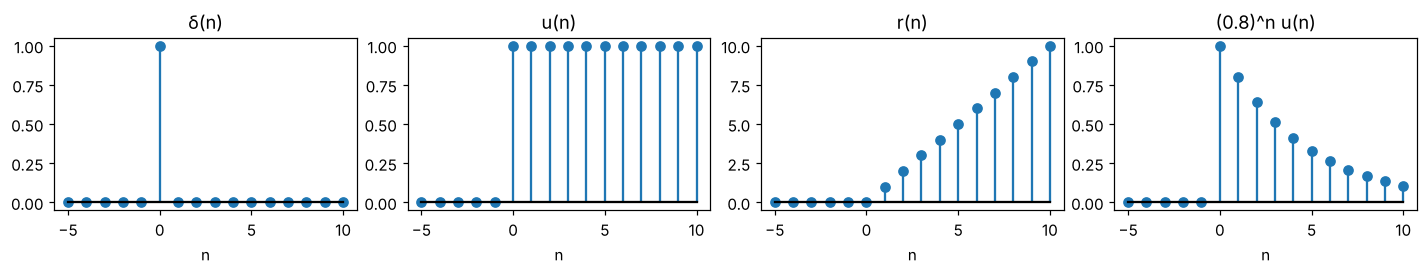

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)          # unit impulse
step  = (n >= 0).astype(float)          # unit step
ramp  = n * step                        # unit ramp
expo  = 0.8**n * step                   # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

## Task 1.2 – Change the parameters
### (1) Plot $(a)^n u(n)$ for $a = 0.5$, $a = -0.8$ and $a = 1.1$ on one figure

a =   0.5:  x(0) = 1.0000,  x(10) = 0.0010,  x(20) = 0.000001
a =  -0.8:  x(0) = 1.0000,  x(10) = 0.1074,  x(20) = 0.011529
a =   1.1:  x(0) = 1.0000,  x(10) = 2.5937,  x(20) = 6.727500


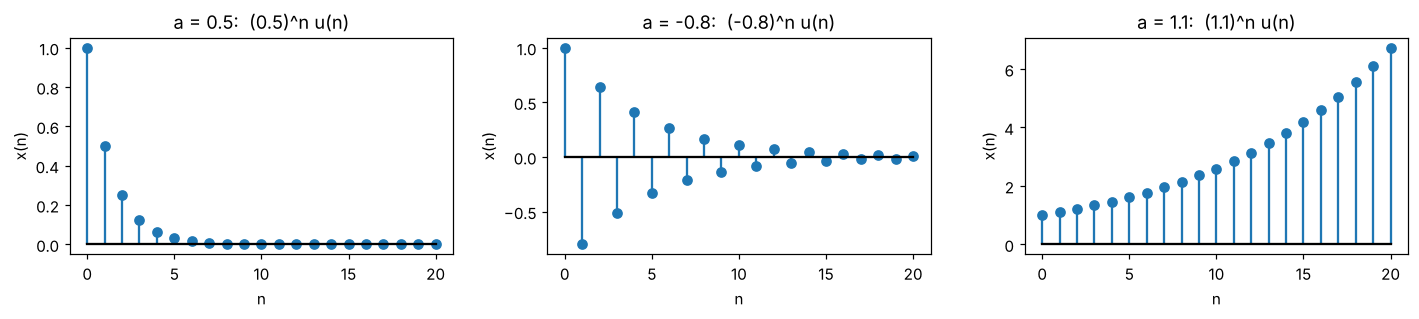

In [3]:
n = np.arange(0, 21)
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a ** n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}:  ({a})^n u(n)")
    ax.set_xlabel("n"); ax.set_ylabel("x(n)")
    print(f"a = {a:5}:  x(0) = {x[0]:.4f},  x(10) = {x[10]:.4f},  x(20) = {x[20]:.6f}")
plt.tight_layout(); plt.show()

**Observation.** For $a=0.5$ the sequence decays smoothly to zero. For $a=-0.8$ it decays too (since $|a|<1$) but its sign alternates at every sample. For $a=1.1$ ($|a|>1$) it grows without bound.

### (2) Plot $\cos(2\pi n/8)$ and $\cos(2\pi n/7.5)$ for $0 \le n \le 40$

cos(2*pi*n/8)   : smallest period N = 8
cos(2*pi*n/7.5) : smallest period N = 15
cos(2*pi*n/7.5) repeats after 8 samples? False


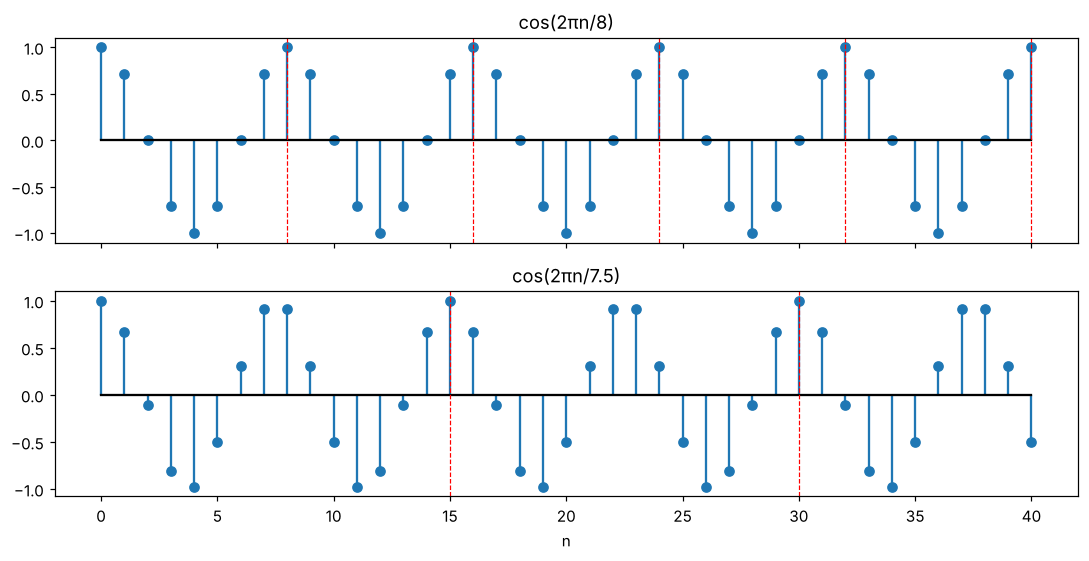

In [4]:
n = np.arange(0, 41)
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
axes[0].stem(n, x1, basefmt="k-"); axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, x2, basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for k in range(8, 41, 8):  axes[0].axvline(k, ls="--", c="r", lw=0.8)   # every 8 samples
for k in range(15, 41, 15): axes[1].axvline(k, ls="--", c="r", lw=0.8)  # every 15 samples
axes[1].set_xlabel("n")
plt.tight_layout(); plt.show()

# numerical check of exact repetition
def smallest_period(x, max_N=20):
    for N in range(1, max_N + 1):
        if np.allclose(x[N:], x[:-N]):
            return N
    return None

print("cos(2*pi*n/8)   : smallest period N =", smallest_period(x1))
print("cos(2*pi*n/7.5) : smallest period N =", smallest_period(x2))
print("cos(2*pi*n/7.5) repeats after 8 samples?", np.allclose(x2[8:], x2[:-8]))

**Which one repeats exactly?** $\cos(2\pi n/8)$ repeats exactly every $N=8$ samples, so it is the one that visibly repeats in $0\le n\le 40$. 
$\cos(2\pi n/7.5)$ has a *continuous-time* period of 7.5, which is not an integer, so it does **not** repeat after 7 or 8 samples. Because $2\pi n/7.5 = 2\pi(2n)/15$, its frequency is the rational number $2/15$ cycles/sample, so it repeats exactly only after $N=15$ samples (two full cycles). (The reason is explained in Week 3: a sinusoid $\cos(2\pi f n)$ is periodic only if $f$ is rational, and the period is the denominator of $f$ in lowest terms.)

## Task 1.3 – Working with audio
The code below loads `my_voice.wav` if it has been uploaded to the Colab Files panel; otherwise it uses a fallback test signal (a decaying 440 Hz tone, 2 s at 16 kHz).

fs = 16000 Hz, duration = 2.00 s, samples = 32000


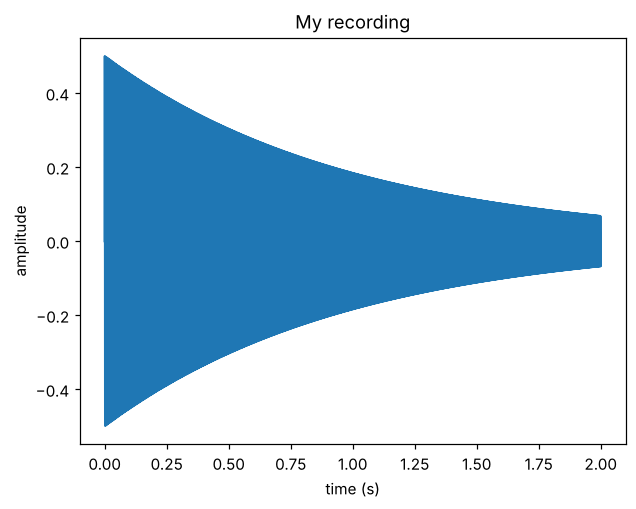

In [5]:
import os
fname = "my_voice.wav"                  # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                      # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))           # normalise to [-1, 1]
else:                                   # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [6]:
from IPython.display import Audio
Audio(x, rate=fs)

## Task 1.5 – Repository and submission
```bash
mkdir COU07506-labs && cd COU07506-labs
git init
cp /path/to/COU07506_Week01_240141481307.ipynb .
git add .
git commit -m "Week 1 lab: discrete-time signals and audio"
git branch -M main
git remote add origin https://github.com/<your-username>/COU07506-labs.git
git push -u origin main
```
**Repository link:** https://github.com/<your-username>/COU07506-labs

## Analysis questions

**Q1. What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?**

The sampling rate is the value `fs` printed by Task 1.3. One minute in mono needs
$$N = f_s \times 60 \ \text{samples (numbers)}.$$

In [7]:
for fs_ in [16000, 44100, 48000]:
    print(f"fs = {fs_:>5} Hz  ->  {fs_*60:>9,} numbers per minute (mono)")
print(f"This notebook's fs = {fs} Hz  ->  {fs*60:,} numbers per minute (mono)")

fs = 16000 Hz  ->    960,000 numbers per minute (mono)
fs = 44100 Hz  ->  2,646,000 numbers per minute (mono)
fs = 48000 Hz  ->  2,880,000 numbers per minute (mono)
This notebook's fs = 16000 Hz  ->  960,000 numbers per minute (mono)


**Q2. Why is a stem plot more appropriate than a continuous line for $x(n)$?**

A discrete-time signal $x(n)$ is defined **only at integer values of $n$**; nothing exists between samples. A stem plot shows exactly these isolated values. A continuous line would wrongly suggest that the signal has values between the integers.

**Q3. For $a=1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?**

If $h(n)=(1.1)^n u(n)$, then $\sum_{n=-\infty}^{\infty}|h(n)| = \sum_{n=0}^{\infty}(1.1)^n = \infty$. The impulse response is not absolutely summable, so the system violates **BIBO (bounded-input bounded-output) stability**. (It is still causal because $h(n)=0$ for $n<0$.) For $|a|<1$ (e.g. 0.5 or −0.8) the sum equals $1/(1-|a|)$, which is finite, so those systems are stable.